# LAB 6 : Naive Bayes Classifier

Task 1: Data Preparation

In [1]:
import pandas as pd

df = pd.read_csv('weather_naive_bayes_40_final.csv')
df.describe()

,Temperature,Humidity,Wind,Precipitation,RainTomorrow
count,40,40,40,40,40
unique,3,3,2,2,2
top,Medium,Low,High,High,No
freq,19,15,21,24,27


In [2]:
df

,Temperature,Humidity,Wind,Precipitation,RainTomorrow
0,Medium,Low,Low,High,Yes
1,Low,Low,High,Low,Yes
2,Medium,High,High,High,No
3,Medium,Medium,High,Low,No
4,Medium,High,Low,High,Yes
5,Medium,Low,High,High,No
6,Low,Medium,High,High,No
7,High,High,High,High,Yes
8,Low,Low,Low,Low,No
9,High,Medium,Low,High,No


In [3]:
print('No of observations :', df.shape[0])
print('No of features :', df.shape[1]-1)

No of observations : 40
No of features : 4


In [4]:
df.shape

(40, 5)

In [5]:
print('Features List')
print(df.columns.tolist())

Features List
['Temperature', 'Humidity', 'Wind', 'Precipitation', 'RainTomorrow']


In [6]:
X = df.drop("RainTomorrow", axis=1)
y = df["RainTomorrow"]

print("Features: ",X.columns.tolist())

print("Target: ", y.name)

Features:  ['Temperature', 'Humidity', 'Wind', 'Precipitation']
Target:  RainTomorrow


In [7]:
print("Class Distribution (%)")
print(df["RainTomorrow"].value_counts(normalize=True)*100)

Class Distribution (%)
RainTomorrow
No     67.5
Yes    32.5
Name: proportion, dtype: float64


In [8]:
df["RainTomorrow"] = df["RainTomorrow"].map({
    "No": 0,
    "Yes": 1
})
df

,Temperature,Humidity,Wind,Precipitation,RainTomorrow
0,Medium,Low,Low,High,1
1,Low,Low,High,Low,1
2,Medium,High,High,High,0
3,Medium,Medium,High,Low,0
4,Medium,High,Low,High,1
5,Medium,Low,High,High,0
6,Low,Medium,High,High,0
7,High,High,High,High,1
8,Low,Low,Low,Low,0
9,High,Medium,Low,High,0


In [9]:
print(df["RainTomorrow"].value_counts())

RainTomorrow
0    27
1    13
Name: count, dtype: int64


In [10]:
train = df.iloc[:30]
test = df.iloc[30:]

In [11]:
X_train = train.drop("RainTomorrow", axis=1)
y_train = train["RainTomorrow"]

X_test = test.drop("RainTomorrow", axis=1)
y_test = test["RainTomorrow"]


In [12]:
print("X_train shape : ", X_train.shape)
print("y_train shape : ", y_train.shape)

print("X_test shape : ", X_test.shape)
print("y_test shape : ", y_test.shape)

X_train shape :  (30, 4)
y_train shape :  (30,)
X_test shape :  (10, 4)
y_test shape :  (10,)


In [13]:
print("Training Dataset: ")
display(train)

Training Dataset: 


,Temperature,Humidity,Wind,Precipitation,RainTomorrow
0,Medium,Low,Low,High,1
1,Low,Low,High,Low,1
2,Medium,High,High,High,0
3,Medium,Medium,High,Low,0
4,Medium,High,Low,High,1
5,Medium,Low,High,High,0
6,Low,Medium,High,High,0
7,High,High,High,High,1
8,Low,Low,Low,Low,0
9,High,Medium,Low,High,0


In [14]:
print("Testing Dataset: ")
display(test)

Testing Dataset: 


,Temperature,Humidity,Wind,Precipitation,RainTomorrow
30,High,High,High,High,0
31,Medium,Low,High,Low,0
32,High,High,Low,Low,1
33,Low,Medium,High,Low,0
34,High,High,Low,High,0
35,Medium,Medium,Low,Low,0
36,Medium,High,Low,High,1
37,Low,Low,Low,Low,0
38,Medium,Low,Low,Low,0
39,Medium,Low,Low,High,0


In [15]:
print("Total observations: ", len(df))
print("Training observations: ",len(train))
print("Testing observations: ", len(test))

print("Training classes: ", y_train.value_counts())

print("Testing classes: ", y_test.value_counts())

Total observations:  40
Training observations:  30
Testing observations:  10
Training classes:  RainTomorrow
0    19
1    11
Name: count, dtype: int64
Testing classes:  RainTomorrow
0    8
1    2
Name: count, dtype: int64


Task 2: Naive Bayes without Laplace Smoothing

In [16]:
class_counts = y_train.value_counts()

print("Class counts:")
print(class_counts)

Class counts:
RainTomorrow
0    19
1    11
Name: count, dtype: int64


In [17]:
N = len(y_train)

P_no = class_counts.get(0, 0) / N
P_yes = class_counts.get(1, 0) / N

print("P(RainTomorrow = No)  =", P_no)
print("P(RainTomorrow = Yes) =", P_yes)

P(RainTomorrow = No)  = 0.6333333333333333
P(RainTomorrow = Yes) = 0.36666666666666664


In [18]:
features = ["Temperature", "Humidity", "Wind", "Precipitation"]

for feature in features:
    print(f"\n{feature}:")
    print(X_train[feature].unique())


Temperature:
['Medium' 'Low' 'High']

Humidity:
['Low' 'High' 'Medium']

Wind:
['Low' 'High']

Precipitation:
['High' 'Low']


In [19]:
def conditional_probability(feature, value, class_value):
    """
    P(feature = value | RainTomorrow = class_value)
    """
    class_data = train[train["RainTomorrow"] == class_value]
    matching_count = (class_data[feature] == value).sum()
    class_count = len(class_data)
    probability = matching_count / class_count

    return probability

In [20]:
p = conditional_probability("Temperature", "High", 1)

print("P(Temperature = High | RainTomorrow = Yes) =", p)

P(Temperature = High | RainTomorrow = Yes) = 0.2727272727272727


In [21]:
p = conditional_probability("Temperature", "High", 0)

print("P(Temperature = High | RainTomorrow = No) =", p)

P(Temperature = High | RainTomorrow = No) = 0.15789473684210525


In [22]:
conditional_probs = {}

for feature in features:
    conditional_probs[feature] = {}

    for value in X_train[feature].unique():
        conditional_probs[feature][value] = {
            0: conditional_probability(feature, value, 0),
            1: conditional_probability(feature, value, 1)
        }

conditional_probs

{'Temperature': {'Medium': {0: np.float64(0.47368421052631576),
   1: np.float64(0.45454545454545453)},
  'Low': {0: np.float64(0.3684210526315789),
   1: np.float64(0.2727272727272727)},
  'High': {0: np.float64(0.15789473684210525),
   1: np.float64(0.2727272727272727)}},
 'Humidity': {'Low': {0: np.float64(0.47368421052631576),
   1: np.float64(0.18181818181818182)},
  'High': {0: np.float64(0.2631578947368421),
   1: np.float64(0.5454545454545454)},
  'Medium': {0: np.float64(0.2631578947368421),
   1: np.float64(0.2727272727272727)}},
 'Wind': {'Low': {0: np.float64(0.3684210526315789),
   1: np.float64(0.45454545454545453)},
  'High': {0: np.float64(0.631578947368421),
   1: np.float64(0.5454545454545454)}},
 'Precipitation': {'High': {0: np.float64(0.7894736842105263),
   1: np.float64(0.45454545454545453)},
  'Low': {0: np.float64(0.21052631578947367),
   1: np.float64(0.5454545454545454)}}}

In [23]:
rows = []

for feature in features:
    for value in X_train[feature].unique():
        rows.append({
            "Feature": feature,
            "Value": value,
            "P(Value | No)": conditional_probs[feature][value][0],
            "P(Value | Yes)": conditional_probs[feature][value][1]
        })

conditional_table = pd.DataFrame(rows)

display(conditional_table)

,Feature,Value,P(Value | No),P(Value | Yes)
0,Temperature,Medium,0.473684,0.454545
1,Temperature,Low,0.368421,0.272727
2,Temperature,High,0.157895,0.272727
3,Humidity,Low,0.473684,0.181818
4,Humidity,High,0.263158,0.545455
5,Humidity,Medium,0.263158,0.272727
6,Wind,Low,0.368421,0.454545
7,Wind,High,0.631579,0.545455
8,Precipitation,High,0.789474,0.454545
9,Precipitation,Low,0.210526,0.545455


In [24]:
zero_probabilities = conditional_table[
    (conditional_table["P(Value | No)"] == 0) |
    (conditional_table["P(Value | Yes)"] == 0)
]

print("Conditional probabilities equal to zero:")
display(zero_probabilities)

Conditional probabilities equal to zero:


,Feature,Value,P(Value | No),P(Value | Yes)


In [25]:
def calculate_scores(row):
    """
    Calculate Naive Bayes scores for No and Yes
    without Laplace smoothing.
    """

    # Start with prior probabilities
    score_no = P_no
    score_yes = P_yes

    # Multiply by conditional probabilities
    for feature in features:
        value = row[feature]

        score_no *= conditional_probs[feature][value][0]
        score_yes *= conditional_probs[feature][value][1]

    return score_no, score_yes

In [26]:
results = []

for index, row in test.iterrows():

    score_no, score_yes = calculate_scores(row)

    if score_yes > score_no:
        prediction = 1
    else:
        prediction = 0

    results.append({
        "Index": index,
        "Score_No": score_no,
        "Score_Yes": score_yes,
        "Predicted": prediction,
        "Actual": row["RainTomorrow"]
    })

results_df = pd.DataFrame(results)

display(results_df)

,Index,Score_No,Score_Yes,Predicted,Actual
0,30,0.013121,0.013524,1,0
1,31,0.018895,0.009016,0,0
2,32,0.002041,0.013524,1,1
3,33,0.008164,0.008114,0,0
4,34,0.007654,0.011270,1,0
5,35,0.006123,0.011270,1,0
6,36,0.022963,0.018783,0,1
7,37,0.008573,0.004508,0,0
8,38,0.011022,0.007513,0,0
9,39,0.041333,0.006261,0,0


In [27]:
results_df["Predicted_Class"] = results_df["Predicted"].map({
    0: "No",
    1: "Yes"
})

results_df["Actual_Class"] = results_df["Actual"].map({
    0: "No",
    1: "Yes"
})

display(
    results_df[
        ["Index", "Score_No", "Score_Yes",
         "Predicted_Class", "Actual_Class"]
    ]
)

,Index,Score_No,Score_Yes,Predicted_Class,Actual_Class
0,30,0.013121,0.013524,Yes,No
1,31,0.018895,0.009016,No,No
2,32,0.002041,0.013524,Yes,Yes
3,33,0.008164,0.008114,No,No
4,34,0.007654,0.011270,Yes,No
5,35,0.006123,0.011270,Yes,No
6,36,0.022963,0.018783,No,Yes
7,37,0.008573,0.004508,No,No
8,38,0.011022,0.007513,No,No
9,39,0.041333,0.006261,No,No


In [28]:
zero_frequency_cases = []

for index, row in test.iterrows():

    zero_features = []

    for feature in features:
        value = row[feature]

        p_no = conditional_probs[feature][value][0]
        p_yes = conditional_probs[feature][value][1]

        if p_no == 0:
            zero_features.append(
                f"{feature}={value} for No"
            )

        if p_yes == 0:
            zero_features.append(
                f"{feature}={value} for Yes"
            )

    if zero_features:
        zero_frequency_cases.append({
            "Index": index,
            "Zero Probability Conditions": ", ".join(zero_features)
        })

zero_frequency_df = pd.DataFrame(zero_frequency_cases)

display(zero_frequency_df)

""


In [29]:
y_true = results_df["Actual"]
y_pred = results_df["Predicted"]

TP = ((y_true == 1) & (y_pred == 1)).sum()
TN = ((y_true == 0) & (y_pred == 0)).sum()
FP = ((y_true == 0) & (y_pred == 1)).sum()
FN = ((y_true == 1) & (y_pred == 0)).sum()

print("True Positives :", TP)
print("True Negatives :", TN)
print("False Positives:", FP)
print("False Negatives:", FN)

True Positives : 1
True Negatives : 5
False Positives: 3
False Negatives: 1


In [30]:
accuracy = (TP + TN) / (TP + TN + FP + FN)

precision = TP / (TP + FP) if (TP + FP) != 0 else 0

recall = TP / (TP + FN) if (TP + FN) != 0 else 0

f1 = (
    2 * precision * recall / (precision + recall)
    if (precision + recall) != 0
    else 0
)

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1-score :", f1)

Accuracy : 0.6
Precision: 0.25
Recall   : 0.5
F1-score : 0.3333333333333333


Task 3: Laplace Smoothing

In [31]:
features = [
    "Temperature",
    "Humidity",
    "Wind",
    "Precipitation"
]

feature_values = {}

for feature in features:
    feature_values[feature] = X_train[feature].unique()

    print(
        feature,
        "->",
        feature_values[feature],
        "-> k =",
        len(feature_values[feature])
    )

Temperature -> ['Medium' 'Low' 'High'] -> k = 3
Humidity -> ['Low' 'High' 'Medium'] -> k = 3
Wind -> ['Low' 'High'] -> k = 2
Precipitation -> ['High' 'Low'] -> k = 2


In [32]:
def laplace_probability(feature, value, class_value):

    # Select observations belonging to this class
    class_data = train[
        train["RainTomorrow"] == class_value
    ]

    # Count occurrences of this feature value
    count = (
        class_data[feature] == value
    ).sum()

    # Number of observations in this class
    class_count = len(class_data)

    # Number of possible values for this feature
    k = len(feature_values[feature])

    # Laplace-smoothed probability
    probability = (count + 1) / (class_count + k)

    return probability

In [33]:
p = laplace_probability(
    "Temperature",
    "High",
    1
)

print(
    "P(Temperature=High | RainTomorrow=Yes) =",
    p
)

P(Temperature=High | RainTomorrow=Yes) = 0.2857142857142857


In [34]:
smoothed_probs = {}

for feature in features:

    smoothed_probs[feature] = {}

    for value in feature_values[feature]:

        smoothed_probs[feature][value] = {
            0: laplace_probability(
                feature,
                value,
                0
            ),
            1: laplace_probability(
                feature,
                value,
                1
            )
        }

In [35]:
rows = []

for feature in features:

    for value in feature_values[feature]:

        rows.append({
            "Feature": feature,
            "Value": value,
            "P(Value | No)": smoothed_probs[
                feature
            ][value][0],
            "P(Value | Yes)": smoothed_probs[
                feature
            ][value][1]
        })

smoothed_table = pd.DataFrame(rows)

display(smoothed_table)

,Feature,Value,P(Value | No),P(Value | Yes)
0,Temperature,Medium,0.454545,0.428571
1,Temperature,Low,0.363636,0.285714
2,Temperature,High,0.181818,0.285714
3,Humidity,Low,0.454545,0.214286
4,Humidity,High,0.272727,0.500000
5,Humidity,Medium,0.272727,0.285714
6,Wind,Low,0.380952,0.461538
7,Wind,High,0.619048,0.538462
8,Precipitation,High,0.761905,0.461538
9,Precipitation,Low,0.238095,0.538462


In [36]:
display(conditional_table)
display(smoothed_table)

,Feature,Value,P(Value | No),P(Value | Yes)
0,Temperature,Medium,0.473684,0.454545
1,Temperature,Low,0.368421,0.272727
2,Temperature,High,0.157895,0.272727
3,Humidity,Low,0.473684,0.181818
4,Humidity,High,0.263158,0.545455
5,Humidity,Medium,0.263158,0.272727
6,Wind,Low,0.368421,0.454545
7,Wind,High,0.631579,0.545455
8,Precipitation,High,0.789474,0.454545
9,Precipitation,Low,0.210526,0.545455


,Feature,Value,P(Value | No),P(Value | Yes)
0,Temperature,Medium,0.454545,0.428571
1,Temperature,Low,0.363636,0.285714
2,Temperature,High,0.181818,0.285714
3,Humidity,Low,0.454545,0.214286
4,Humidity,High,0.272727,0.500000
5,Humidity,Medium,0.272727,0.285714
6,Wind,Low,0.380952,0.461538
7,Wind,High,0.619048,0.538462
8,Precipitation,High,0.761905,0.461538
9,Precipitation,Low,0.238095,0.538462


In [37]:
print(
    "Number of zero probabilities:",
    (
        smoothed_table[
            ["P(Value | No)", "P(Value | Yes)"]
        ] == 0
    ).sum().sum()
)

Number of zero probabilities: 0


In [38]:
def calculate_smoothed_scores(row):

    # Start with prior probabilities
    score_no = P_no
    score_yes = P_yes

    # Multiply by smoothed conditional probabilities
    for feature in features:

        value = row[feature]

        score_no *= smoothed_probs[
            feature
        ][value][0]

        score_yes *= smoothed_probs[
            feature
        ][value][1]

    return score_no, score_yes

In [39]:
smoothed_results = []

for index, row in test.iterrows():

    score_no, score_yes = calculate_smoothed_scores(row)

    if score_yes > score_no:
        prediction = 1
    else:
        prediction = 0

    smoothed_results.append({
        "Index": index,
        "Score_No": score_no,
        "Score_Yes": score_yes,
        "Predicted": prediction,
        "Actual": row["RainTomorrow"]
    })

smoothed_results_df = pd.DataFrame(
    smoothed_results
)

In [40]:
smoothed_results_df["Predicted_Class"] = (
    smoothed_results_df["Predicted"].map({
        0: "No",
        1: "Yes"
    })
)

smoothed_results_df["Actual_Class"] = (
    smoothed_results_df["Actual"].map({
        0: "No",
        1: "Yes"
    })
)

display(
    smoothed_results_df[
        [
            "Index",
            "Score_No",
            "Score_Yes",
            "Predicted_Class",
            "Actual_Class"
        ]
    ]
)

,Index,Score_No,Score_Yes,Predicted_Class,Actual_Class
0,30,0.014812,0.013018,No,No
1,31,0.019287,0.009763,No,No
2,32,0.002849,0.013018,Yes,Yes
3,33,0.009258,0.008679,No,No
4,34,0.009115,0.011158,Yes,No
5,35,0.007121,0.011158,Yes,No
6,36,0.022788,0.016737,No,Yes
7,37,0.009495,0.005579,No,No
8,38,0.011869,0.008369,No,No
9,39,0.037980,0.007173,No,No


In [41]:
y_true_smooth = smoothed_results_df["Actual"]
y_pred_smooth = smoothed_results_df["Predicted"]

TP_s = (
    (y_true_smooth == 1) &
    (y_pred_smooth == 1)
).sum()

TN_s = (
    (y_true_smooth == 0) &
    (y_pred_smooth == 0)
).sum()

FP_s = (
    (y_true_smooth == 0) &
    (y_pred_smooth == 1)
).sum()

FN_s = (
    (y_true_smooth == 1) &
    (y_pred_smooth == 0)
).sum()

print("True Positives :", TP_s)
print("True Negatives :", TN_s)
print("False Positives:", FP_s)
print("False Negatives:", FN_s)

True Positives : 1
True Negatives : 6
False Positives: 2
False Negatives: 1


In [42]:
accuracy_s = (
    (TP_s + TN_s) /
    (TP_s + TN_s + FP_s + FN_s)
)

precision_s = (
    TP_s / (TP_s + FP_s)
    if (TP_s + FP_s) != 0
    else 0
)

recall_s = (
    TP_s / (TP_s + FN_s)
    if (TP_s + FN_s) != 0
    else 0
)

f1_s = (
    2 * precision_s * recall_s /
    (precision_s + recall_s)
    if (precision_s + recall_s) != 0
    else 0
)

In [43]:
metrics_smoothed = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score"
    ],
    "Score": [
        accuracy_s,
        precision_s,
        recall_s,
        f1_s
    ]
})

display(metrics_smoothed)

,Metric,Score
0,Accuracy,0.700000
1,Precision,0.333333
2,Recall,0.500000
3,F1-score,0.400000


Task 4: Comparison of Naive Bayes with and Without Laplace Smoothing

In [44]:
prediction_comparison = pd.DataFrame({
    "Test Sample": [
        f"T{i}" for i in range(1, 11)
    ],

    "Actual Class": results_df["Actual_Class"].values,

    "Without Smoothing": results_df[
        "Predicted_Class"
    ].values,

    "With Laplace Smoothing": smoothed_results_df[
        "Predicted_Class"
    ].values
})

display(prediction_comparison)

,Test Sample,Actual Class,Without Smoothing,With Laplace Smoothing
0,T1,No,Yes,No
1,T2,No,No,No
2,T3,Yes,Yes,Yes
3,T4,No,No,No
4,T5,No,Yes,Yes
5,T6,No,Yes,Yes
6,T7,Yes,No,No
7,T8,No,No,No
8,T9,No,No,No
9,T10,No,No,No


In [45]:
performance_comparison = pd.DataFrame({
    "Performance Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score"
    ],

    "Without Smoothing": [
        accuracy,
        precision,
        recall,
        f1
    ],

    "With Laplace Smoothing": [
        accuracy_s,
        precision_s,
        recall_s,
        f1_s
    ]
})

display(performance_comparison)

,Performance Metric,Without Smoothing,With Laplace Smoothing
0,Accuracy,0.600000,0.700000
1,Precision,0.250000,0.333333
2,Recall,0.500000,0.500000
3,F1-score,0.333333,0.400000


Task 5: Visualization

In [46]:
import numpy as np
import matplotlib.pyplot as plt

metrics = ["Accuracy", "Precision", "Recall", "F1-score"]

without_smoothing = [
    accuracy,
    precision,
    recall,
    f1
]

with_smoothing = [
    accuracy_s,
    precision_s,
    recall_s,
    f1_s
]

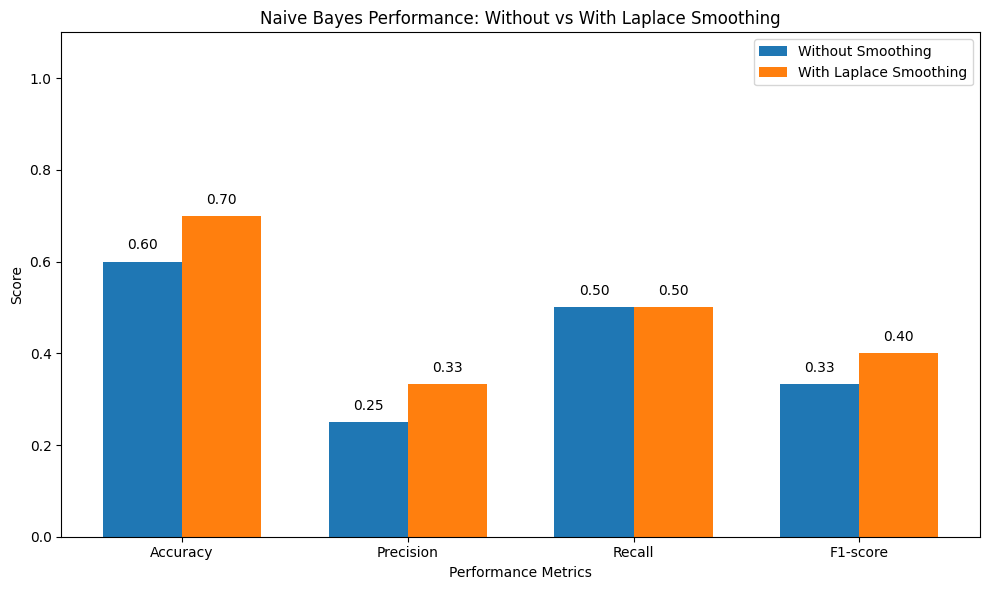

In [47]:
x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

bars1 = ax.bar(
    x - width/2,
    without_smoothing,
    width,
    label="Without Smoothing"
)

bars2 = ax.bar(
    x + width/2,
    with_smoothing,
    width,
    label="With Laplace Smoothing"
)

# Axis labels and title
ax.set_xlabel("Performance Metrics")
ax.set_ylabel("Score")
ax.set_title("Naive Bayes Performance: Without vs With Laplace Smoothing")

# X-axis labels
ax.set_xticks(x)
ax.set_xticklabels(metrics)

# Keep scores between 0 and 1
ax.set_ylim(0, 1.1)

# Legend
ax.legend()

# Add value labels above each bar
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width()/2,
            height + 0.02,
            f"{height:.2f}",
            ha="center",
            va="bottom"
        )

plt.tight_layout()
plt.show()